# RoboCasa with a RoboJEPA baseline

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/envs/robocasa.ipynb)

[RoboCasa](https://robocasa.ai) is a kitchen benchmark in MuJoCo: a mobile Franka arm performs 365 tasks across thousands of procedurally generated kitchens, specified in language. Here the task is `OpenDrawer`, "Open the left drawer" or "Open the right drawer", and the data are RoboCasa's 102 human demonstrations of it.

The baseline is the same simple [RoboJEPA](../../docs/models/jepa/robojepa.md) as the OGBench and RoboDojo notebooks: one camera, raw 8 × 8 pixel patches, CEM planning. RoboCasa states goals in language, so the planner is scored on held-out demonstrations: `reset(scenes=...)` restores a demonstration's kitchen and initial state, the goal is that demonstration's final frame, and RoboCasa's own success check decides the outcome.

RoboCasa runs in its own environment (it pins MuJoCo 3.3.1) with its kitchen assets; see the [benchmark guide](../../docs/guides/benchmark-environments.md#robocasa).

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples,robocasa]"

In [1]:
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from robocasa.scripts.download_datasets import download_datasets
from robocasa.utils.dataset_registry_utils import get_ds_path
from torch import nn
from torch.utils.data import ConcatDataset, DataLoader

from torch_world import plots
from torch_world.datasets import TrajectoryDataset, load_robocasa, load_robocasa_scene
from torch_world.envs import RoboCasa
from torch_world.models import RoboJEPA
from torch_world.planning import CEM, RecedingHorizon

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
amp = torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda")  # bf16 matmuls on CUDA
TASK, CAMERA, FRAMESKIP, WINDOW, GRID, SIZE = "OpenDrawer", "robot0_agentview_left", 5, 4, (8, 8), 64

[robosuite WARNING] No private macro file found! (macros.py:57)


[robosuite WARNING] It is recommended to use a private macro file (macros.py:58)


[robosuite WARNING] To setup, run: python /clusterhome/kleyton/pytorch-world-benchmarks-20261018/third_party/robosuite/robosuite/scripts/setup_macros.py (macros.py:59)


[robosuite WARNING] Could not import robosuite_models. Some robots may not be available. If you want to use these robots, please install robosuite_models from source (https://github.com/ARISE-Initiative/robosuite_models) or through pip install. (__init__.py:30)


[robosuite WARNING] Could not load the mink-based whole-body IK. Make sure you install related import properly (e.g. pip install mink==0.0.5), otherwise you will not be able to use the default IK controller setting for GR1 robot. (__init__.py:40)


## Data

RoboCasa's downloader fetches the pretraining demonstrations of the task (71 MB). `load_robocasa` reads one episode: the left agent-view camera at 64 × 64 and the 12 controls in the order the environment takes them. Ten demonstrations are held out.

Task: OpenDrawer
Split: pretrain
Source: human
Dataset already exists under /clusterhome/kleyton/pytorch-world-benchmarks-20261018/third_party/robocasa/datasets/v1.0/pretrain/atomic/OpenDrawer/20250819/lerobot
Skipping.



102 demonstrations of 135 to 250 steps at 20 Hz


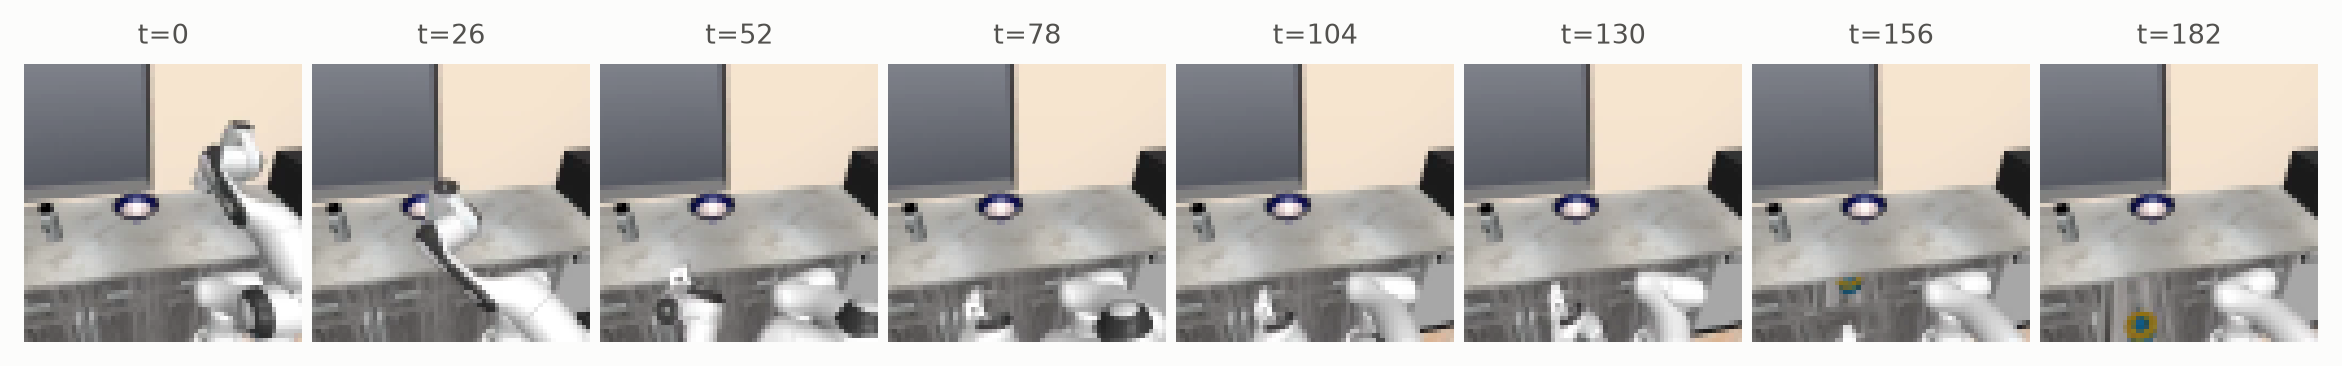

In [2]:
ROOT = get_ds_path(TASK, "human", split="pretrain")
download_datasets(split=["pretrain"], tasks=[TASK], source=["human"])  # skips a dataset already present
num_episodes = len(list(Path(ROOT).glob("data/*/episode_*.parquet")))
episodes = [load_robocasa(ROOT, i, camera=CAMERA, size=SIZE) for i in range(num_episodes)]
train, held_out = episodes[:-10], list(range(num_episodes - 10, num_episodes))
lengths = [e["actions"].shape[1] for e in episodes]
print(f"{num_episodes} demonstrations of {min(lengths)} to {max(lengths)} steps at 20 Hz")
loader = DataLoader(
    ConcatDataset([TrajectoryDataset(e, window=WINDOW, frameskip=FRAMESKIP) for e in train]),
    batch_size=64, shuffle=True, drop_last=True,
)
first = episodes[0]["observations"][0]
plots.images(first[:: len(first) // 7][:8], [f"t={t}" for t in range(0, len(first), len(first) // 7)][:8])

## Model

One token per chunk of five 12-value controls, and 64 patch tokens per frame.

In [3]:
class Patchify(nn.Module):
    def forward(self, x):
        return F.pixel_unshuffle(x, 8).flatten(2).transpose(1, 2)


def frames(observations):
    x = observations.float() / 255 if observations.dtype == torch.uint8 else observations
    return x.unsqueeze(2)


model = RoboJEPA(
    embed_dim=192, action_dim=12 * FRAMESKIP, num_views=1, predictor_dim=256, depth=6, num_heads=4,
    window=WINDOW, rollout_steps=2, encoder=Patchify(),
).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

4.85M parameters


## Train

6000 updates in 20.7 min


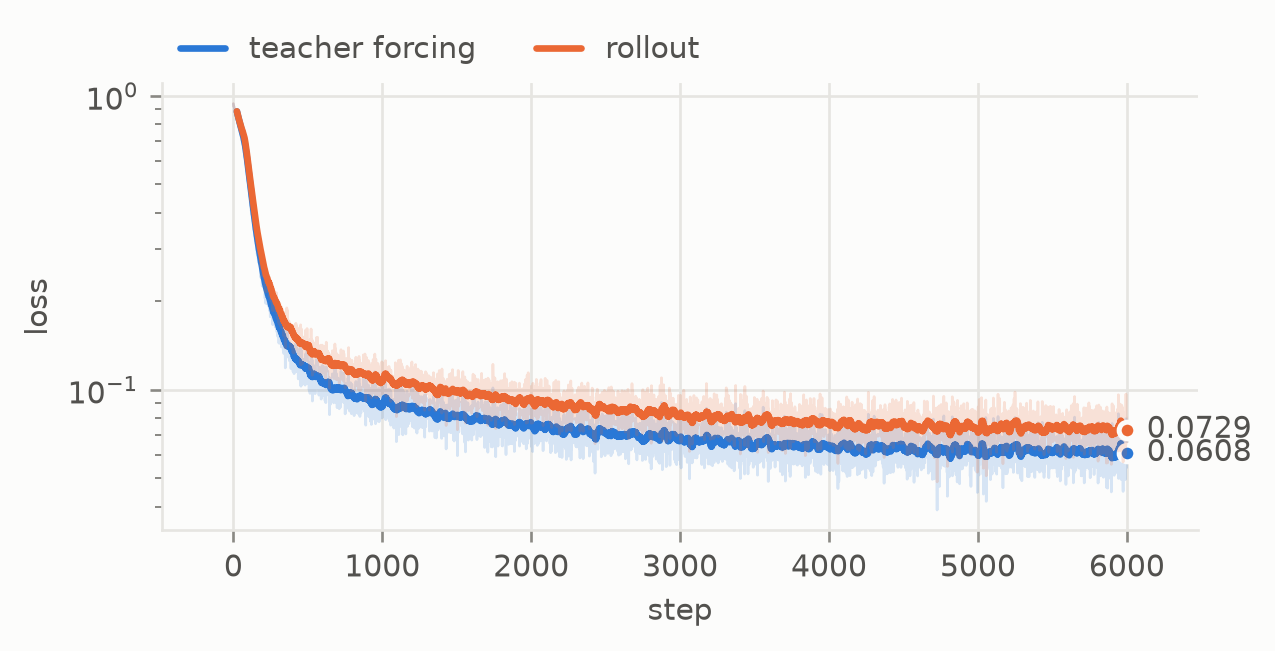

In [4]:
STEPS = 6000
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.04)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-4, total_steps=STEPS, pct_start=0.05)
log, step, tic = {"teacher forcing": [], "rollout": []}, 0, time.perf_counter()
model.train()
while step < STEPS:
    for batch in loader:
        z = model.encode(frames(batch["observations"].to(device)), GRID)
        with amp:
            out = model(z, batch["actions"].to(device))
        opt.zero_grad(set_to_none=True)
        out["loss"].backward()
        opt.step()
        sched.step()
        log["teacher forcing"].append(out["tf_loss"].item())
        log["rollout"].append(out["rollout_loss"].item())
        step += 1
        if step == STEPS:
            break
model.eval()
print(f"{STEPS} updates in {(time.perf_counter() - tic) / 60:.1f} min")
plots.curves(log)

## Held-out prediction

Next-latent error on the held-out demonstrations, against copying the last latent forward and against the model given the actions of another moment.

In [5]:
errors = {"RoboJEPA": [], "RoboJEPA, shuffled actions": [], "persistence": []}
with torch.no_grad():
    for i in held_out:
        data = TrajectoryDataset(episodes[i], window=WINDOW, frameskip=FRAMESKIP)
        batch = [data[j] for j in range(len(data))]
        z = model.encode(frames(torch.stack([b["observations"] for b in batch]).to(device)), GRID)
        actions = torch.stack([b["actions"] for b in batch]).to(device)
        shuffled = actions[torch.randperm(len(actions), generator=torch.Generator().manual_seed(0))]
        with amp:
            pred = model.predict(z[:, :-1], actions[:, :-1]).float()
            wrong = model.predict(z[:, :-1], shuffled[:, :-1]).float()
        errors["RoboJEPA"].append((pred[:, -1] - z[:, -1]).abs().mean().item())
        errors["RoboJEPA, shuffled actions"].append((wrong[:, -1] - z[:, -1]).abs().mean().item())
        errors["persistence"].append((z[:, -2] - z[:, -1]).abs().mean().item())
for name, e in errors.items():
    print(f"{name:28s} next-latent L1 {np.mean(e):.4f}")

RoboJEPA                     next-latent L1 0.0790
RoboJEPA, shuffled actions   next-latent L1 0.0940
persistence                  next-latent L1 0.0763


## Reach held-out goals in the simulator

Each held-out demonstration's kitchen and initial state are restored, and its final frame is the goal. CEM plans five chunks of five controls toward the goal's embedding; the robot runs two chunks, then the planner looks again. Episodes end at RoboCasa's success check, or after one and a half times the demonstration's length. Replaying the demonstration's own actions is the upper bound, and confirms each restored scene is solvable; random controls are the floor. On macOS, robosuite renders correctly for one environment per process, so episodes run one at a time.

[robosuite INFO] Loading controller configuration from: /clusterhome/kleyton/pytorch-world-benchmarks-20261018/third_party/robosuite/robosuite/controllers/config/robots/default_pandaomron.json (composite_controller_factory.py:121)


demonstration replay   success 1.00  steps [119, 177, 168, 186, 161, 232, 172, 196, 201, 145]


random                 success 0.00  steps [202, 291, 277, 304, 265, 372, 282, 321, 325, 241]


RoboJEPA + CEM         success 0.00  steps [202, 291, 277, 304, 265, 372, 282, 321, 325, 241]
evaluation in 24.6 min


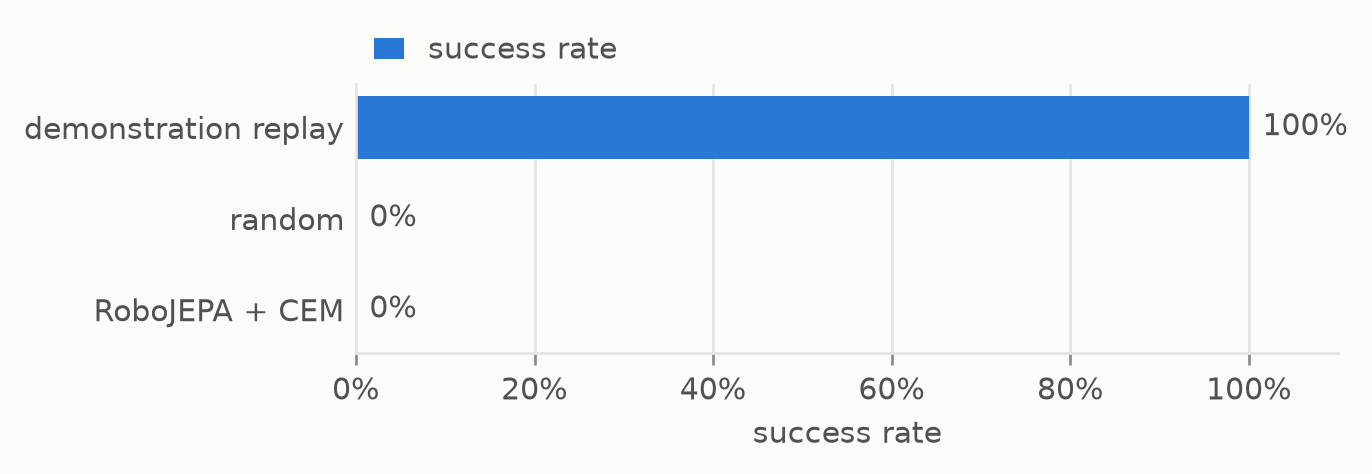

In [6]:
world = RoboCasa(TASK, split="pretrain", batch_size=1, size=SIZE, camera=CAMERA, render_size=128)
planner = CEM(horizon=5, action_dim=12 * FRAMESKIP, num_samples=128, num_elites=16, iterations=5, bounds=(-1, 1))


def run(i, kind, record=False):
    demo = episodes[i]
    world.reset(scenes=[load_robocasa_scene(ROOT, i)])
    goal = model.encode(frames(demo["observations"][:, -1:].to(device)), GRID)[:, 0]
    replay = iter(demo["actions"][0])

    def plan(obs):
        with torch.no_grad(), amp:
            return planner(model, model.encode(frames(obs[:, None].to(device)), GRID), goal).float().cpu()

    policy = {
        "demonstration replay": lambda obs: next(replay, torch.zeros(12))[None],
        "random": lambda obs: torch.rand(1, 12) * 2 - 1,
        "RoboJEPA + CEM": RecedingHorizon(plan, action_dim=12, execute=2),
    }[kind]
    obs, video = world.render(), [world.render_frame()[0]]
    for _ in range(int(1.5 * demo["actions"].shape[1])):
        obs = world.step(policy(obs))
        if record:
            video.append(world.render_frame()[0])
        if world.transition.done[0]:
            break
    return bool(world.transition.success[0]), int(world.elapsed[0]), torch.stack(video)


results, videos, tic = {}, {}, time.perf_counter()
for kind in ("demonstration replay", "random", "RoboJEPA + CEM"):
    outcomes = [run(i, kind, record=i == held_out[0]) for i in held_out]
    results[kind] = {"success rate": float(np.mean([s for s, _, _ in outcomes]))}
    videos[kind] = outcomes[0][2]
    print(f"{kind:22s} success {results[kind]['success rate']:.2f}  steps {[t for _, t, _ in outcomes]}")
print(f"evaluation in {(time.perf_counter() - tic) / 60:.1f} min")
plots.bars(results, xlabel="success rate")

The first held-out episode under each policy, beside the goal frame, from RoboCasa's centered agent view.


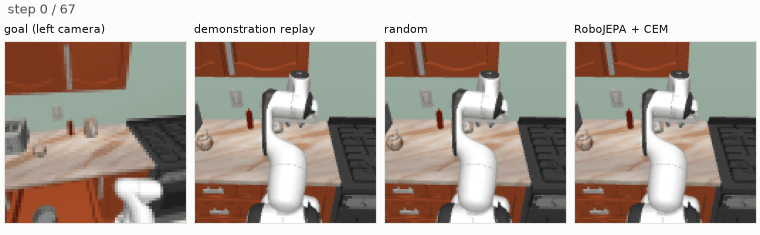

In [7]:
goal = F.interpolate(episodes[held_out[0]]["observations"][0, -1:].float(), (128, 128), mode="nearest")[0].byte()
length = max(len(v) for v in videos.values())
tiles = [goal[None].expand(length, -1, -1, -1)] + [torch.cat([v, v[-1:].expand(length - len(v), -1, -1, -1)]) for v in videos.values()]
animation = plots.episodes(torch.stack(tiles)[:, ::3], titles=["goal (left camera)", *videos], ncols=4, fps=6)
world.close()
animation

Raw pixel patches, 92 demonstrations and 6,000 updates make a deliberately small baseline. RoboCasa's target datasets hold 500 demonstrations per task, and RoboJEPA was designed for a frozen V-JEPA 2.1 encoder; both are the natural next steps. Any registered task works the same way: `RoboCasa(task)` and `load_robocasa` take RoboCasa's task names.